# Step 3 — Split protocol (random vs grouped) and learning curve

Two course requirements, both using extra training runs from `run_step3.sh` / `run_lc.sh`:

**A. Split protocol (rule 5b): naive random split vs our grouped split.**
Our split keeps near-duplicate / same-session groups on one side. Here the baseline and class-weighted
loss are retrained on 3 *naive* stratified random splits of the same sizes (train 14,642 / val 3,677 /
test 3,078). We report both, and measure the leakage directly: how much better a model does on test
images whose near-duplicate was in its training set.

**B. Generalisation study (component 3): performance vs training-set size.**
Baseline and class-weighted loss trained on 5, 10, 25, 50% of the training split (nested stratified
subsets; validation and test unchanged) on validation folds 0–2. 100% = the step 2 runs of folds 0–2.
Smaller subsets were given more epochs (60/40/30/25 for 5/10/25/50%) so they are not undertrained.

This notebook works with whatever runs have finished; re-run it when the queues are done.

Outputs: `reports/figures/split_and_learning_curve/`.

## 1. Setup and loading all runs

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Deep_Learning").is_dir())
sys.path.insert(0, str(ROOT))
from Deep_Learning.config import RUNS_DIR, SPLITS_CSV, short_class_names

CLASSES = short_class_names()
K = len(CLASSES)
OUT = ROOT / "reports" / "figures" / "split_and_learning_curve"
OUT.mkdir(parents=True, exist_ok=True)
METHODS = ["none", "weights"]
LABEL = {"none": "None (baseline)", "weights": "Class-weighted loss"}
COLOR = {"none": "#2a78d6", "weights": "#1baf7a"}
SURFACE, INK, INK_2, GRID = "#ffffff", "#0b0b0b", "#52514e", "#e4e3df"
HALO = dict(boxstyle="square,pad=0.15", fc=SURFACE, ec="none")
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "text.color": INK, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
    "pdf.fonttype": 42, "ps.fonttype": 42, "figure.dpi": 80,
})
pd.set_option("display.precision", 4)

def save(fig, stem):
    fig.savefig(OUT / f"{stem}.png", dpi=300, bbox_inches="tight")
    fig.savefig(OUT / f"{stem}.pdf", bbox_inches="tight")

def clean(ax, grid="y"):
    getattr(ax, f"{grid}axis").grid(True, color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)

splits = pd.read_csv(SPLITS_CSV)              # has group_id for every image
group_of = splits.set_index("image_id").group_id
gsize = splits.set_index("image_id").group_size
grouped_test = splits[splits.split == "test"].reset_index(drop=True)

rows = []
for d in sorted(RUNS_DIR.iterdir()):
    if not (d / "test_metrics.json").exists() or not (d / "config.json").exists():
        continue
    cfg = json.loads((d / "config.json").read_text())
    if cfg["model"] != "resnet50" or cfg["imbalance"] not in METHODS:
        continue
    saved = json.loads((d / "test_metrics.json").read_text())
    split = cfg.get("split", "grouped")
    # test image ids: saved per run since step 3; older (grouped) runs use the grouped test set
    if (d / "split_ids.csv").exists():
        ids = pd.read_csv(d / "split_ids.csv")
    else:
        assert split == "grouped"
        ids = None
    probs = np.load(d / "test_probs.npy")
    test_ids = ids[ids.part == "test"] if ids is not None else grouped_test[["image_id", "label"]]
    y = test_ids.label.to_numpy()
    assert np.isclose(f1_score(y, probs.argmax(1), average="macro"), saved["test_macro_f1"], atol=1e-6), d.name
    rows.append({"run": d.name, "method": cfg["imbalance"], "split": split,
                 "split_seed": cfg.get("split_seed", 0), "fold": cfg["val_fold"],
                 "train_frac": cfg.get("train_frac", 1.0), "epochs": cfg["epochs"],
                 "best_epoch": saved["best_epoch"], "n_train": None if ids is None else int((ids.part == "train").sum()),
                 "acc": saved["test_acc"], "balanced_acc": saved["test_balanced_acc"], "macro_f1": saved["test_macro_f1"],
                 "f1_CBB": f1_score(y, probs.argmax(1), labels=[0], average=None)[0],
                 "ids": ids, "test_ids": test_ids.image_id.to_numpy(), "y": y, "pred": probs.argmax(1)})
R = pd.DataFrame(rows)
R.loc[R.n_train.isna(), "n_train"] = 14642          # full grouped training split (folds differ by a few images)
print(R.groupby(["split", "train_frac", "method"]).size().rename("finished runs").to_string())

split    train_frac  method 
grouped  0.05        none       3
                     weights    3
         0.10        none       3
                     weights    3
         0.25        none       3
                     weights    3
         0.50        none       3
                     weights    3
         1.00        none       5
                     weights    5
random   1.00        none       3
                     weights    3


## 2. A — Random vs grouped split

### 2.1 Headline numbers

Each model is scored on the test set of *its own* split. Grouped: 5 runs (validation folds 0–4),
random: up to 3 runs (3 different random splits). Mean ± std.

In [2]:
full = R[R.train_frac == 1.0]
g = full.groupby(["split", "method"])
headline = (100 * g[["acc", "balanced_acc", "macro_f1"]].agg(["mean", "std"])).round(2)
headline[("runs", "")] = g.size()
headline.to_csv(OUT / "random_vs_grouped_headline.csv")
headline

acc       balanced_acc       macro_f1       runs
                  mean   std         mean   std     mean   std     
split   method                                                     
grouped none     87.78  0.30        77.37  0.95    77.65  0.67    5
        weights  87.76  0.15        79.31  0.65    78.30  0.36    5
random  none     88.50  0.20        78.70  0.69    79.17  0.28    3
        weights  87.49  0.26        78.21  0.44    77.90  0.39    3

In [3]:
diff_rows = []
for me in METHODS:
    g = full[(full.split == "grouped") & (full.method == me)].macro_f1
    r = full[(full.split == "random") & (full.method == me)].macro_f1
    if len(r) >= 2:
        t = stats.ttest_ind(r, g, equal_var=False)
        diff_rows.append({"method": me, "grouped": 100 * g.mean(), "random": 100 * r.mean(),
                          "random − grouped (pp)": 100 * (r.mean() - g.mean()), "Welch p": t.pvalue,
                          "runs (grouped/random)": f"{len(g)}/{len(r)}"})
split_diff = pd.DataFrame(diff_rows)
split_diff.to_csv(OUT / "random_vs_grouped.csv", index=False, float_format="%.4f")
split_diff.round(3)

,method,grouped,random,random − grouped (pp),Welch p,runs (grouped/random)
0,none,77.655,79.171,1.516,0.005,5/3
1,weights,78.301,77.896,-0.405,0.213,5/3


### 2.2 Measuring the leakage directly

Different test sets differ in difficulty, so the headline gap mixes leakage with sampling noise.
A direct measure: in a random split, some test images have a **near-duplicate (same group) in the
training set**. Compare the accuracy on those *leaked* images with images from the same kind of
groups whose members were **not** seen in training:

- **random split, leaked**: test images in a multi-image group with ≥1 member in that run's train set;
- **grouped split, unseen group**: test images in a multi-image group (all members are held out by construction).

Both sets contain only grouped (near-duplicate) images, so the only difference is whether a group-mate was seen.

In [4]:
leak_rows = []
for _, r in full.iterrows():
    gid = group_of.loc[r.test_ids].to_numpy()
    multi = gsize.loc[r.test_ids].to_numpy() > 1
    ok = r.pred == r.y
    if r.split == "random":
        train_groups = set(group_of.loc[r.ids[r.ids.part == "train"].image_id])
        leaked = multi & np.isin(gid, list(train_groups))
        leak_rows.append({"run": r.run, "method": r.method, "split": "random", "subset": "leaked (group-mate in train)",
                          "n": int(leaked.sum()), "acc": ok[leaked].mean()})
        leak_rows.append({"run": r.run, "method": r.method, "split": "random", "subset": "singletons",
                          "n": int((~multi).sum()), "acc": ok[~multi].mean()})
    else:
        leak_rows.append({"run": r.run, "method": r.method, "split": "grouped", "subset": "group, unseen in train",
                          "n": int(multi.sum()), "acc": ok[multi].mean()})
        leak_rows.append({"run": r.run, "method": r.method, "split": "grouped", "subset": "singletons",
                          "n": int((~multi).sum()), "acc": ok[~multi].mean()})
leak = pd.DataFrame(leak_rows)
leak_tab = leak.groupby(["split", "subset", "method"]).agg(images_per_run=("n", "mean"), acc_mean=("acc", "mean"),
                                                        acc_std=("acc", "std"), runs=("acc", "size"))
leak_tab.to_csv(OUT / "leakage_accuracy.csv", float_format="%.4f")
leak_tab.assign(acc_mean=lambda d: (100 * d.acc_mean).round(1), acc_std=lambda d: (100 * d.acc_std).round(1))

images_per_run  acc_mean  \
split   subset                       method                              
grouped group, unseen in train       none           150.0000      82.0   
                                     weights        150.0000      83.1   
        singletons                   none          2928.0000      88.1   
                                     weights       2928.0000      88.0   
random  leaked (group-mate in train) none           113.3333      84.3   
                                     weights        113.3333      84.2   
        singletons                   none          2950.6667      88.6   
                                     weights       2950.6667      87.6   

                                              acc_std  runs  
split   subset                       method                  
grouped group, unseen in train       none         0.5     5  
                                     weights      1.8     5  
        singletons                   none         0.3     5  
                                     weights      0.2     5  
random  leaked (group-mate in train) none         3.9     3  
                                     weights      3.9     3  
        singletons                   none         0.3     3  
                                     weights      0.4     3

In [5]:
# Class mix of the two near-duplicate subsets compared above (they are different images),
# so a gap in accuracy can be read against a difference in which classes they contain.
mix_rows = []
for _, r in full.iterrows():
    multi = gsize.loc[r.test_ids].to_numpy() > 1
    if r.split == "random":
        gid = group_of.loc[r.test_ids].to_numpy()
        sel = multi & np.isin(gid, list(set(group_of.loc[r.ids[r.ids.part == "train"].image_id])))
        name = "random: leaked"
    else:
        sel, name = multi, "grouped: group, unseen in train"
    mix_rows.append(pd.Series(np.bincount(r.y[sel], minlength=K) / max(sel.sum(), 1), index=CLASSES, name=name))
mix = pd.DataFrame(mix_rows).groupby(level=0).mean()
mix.loc["whole test set"] = np.bincount(grouped_test.label, minlength=K) / len(grouped_test)
(100 * mix).round(1)

,CBB,CBSD,CGM,CMD,Healthy
"grouped: group, unseen in train",5.3,10.7,9.3,25.3,49.3
random: leaked,8.0,21.6,13.2,21.6,35.6
whole test set,4.8,9.9,11.2,61.1,12.9


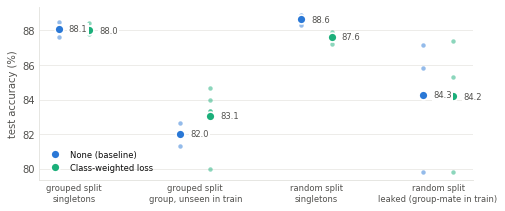

In [6]:
order = [("grouped", "singletons"), ("grouped", "group, unseen in train"),
         ("random", "singletons"), ("random", "leaked (group-mate in train)")]
fig, ax = plt.subplots(figsize=(7, 2.8))
for j, me in enumerate(METHODS):
    for i, (sp, sub) in enumerate(order):
        v = 100 * leak[(leak.split == sp) & (leak.subset == sub) & (leak.method == me)].acc
        if len(v) == 0:
            continue
        x = i + (j - 0.5) * 0.25
        ax.plot(np.full(len(v), x), v, "o", ms=4, color=COLOR[me], alpha=0.5, mew=0)
        ax.plot(x, v.mean(), "o", ms=8, color=COLOR[me], mec=SURFACE, mew=1.5, label=LABEL[me] if i == 0 else None)
        ax.annotate(f"{v.mean():.1f}", (x, v.mean()), xytext=(9, 0), textcoords="offset points",
                    va="center", fontsize=7.5, color=INK_2, bbox=HALO)
ax.set_xticks(range(len(order)), [f"{sp} split\n{sub}" for sp, sub in order], fontsize=7.5)
ax.set_ylabel("test accuracy (%)")
ax.legend(frameon=False, fontsize=7.5, loc="lower left")
clean(ax)
save(fig, "leakage_accuracy")
plt.show()

## 3. B — Learning curve

### 3.1 Undertraining check

If the best epoch is (close to) the last epoch, the run was still improving when it stopped.

In [7]:
G = R[(R.split == "grouped") & (R.fold.isin([0, 1, 2]))].copy()
G["pct"] = (100 * G.train_frac).round().astype(int)
chk = G.assign(at_end=G.best_epoch >= G.epochs - 1)[["run", "pct", "method", "fold", "epochs", "best_epoch", "at_end"]]
print(f"{chk.at_end.sum()} of {len(chk)} runs had their best epoch in the last 2 epochs")
chk.sort_values(["pct", "method", "fold"]).set_index("run")

1 of 30 runs had their best epoch in the last 2 epochs


,pct,method,fold,epochs,best_epoch,at_end
run,,,,,,
lc05_none_f0,5,none,0,60,59,True
lc05_none_f1,5,none,1,60,28,False
lc05_none_f2,5,none,2,60,9,False
lc05_weights_f0,5,weights,0,60,10,False
lc05_weights_f1,5,weights,1,60,12,False
lc05_weights_f2,5,weights,2,60,12,False
lc10_none_f0,10,none,0,40,20,False
lc10_none_f1,10,none,1,40,13,False
lc10_none_f2,10,none,2,40,8,False


### 3.2 Scores vs training-set size

Mean ± std over validation folds 0–2. `n_train` = number of training images.

In [8]:
lc = G.groupby(["pct", "method"]).agg(n_train=("n_train", "mean"), runs=("run", "size"),
                                      macro_f1=("macro_f1", "mean"), macro_f1_std=("macro_f1", "std"),
                                      balanced_acc=("balanced_acc", "mean"), balanced_acc_std=("balanced_acc", "std"),
                                      f1_CBB=("f1_CBB", "mean"), f1_CBB_std=("f1_CBB", "std"))
lc.to_csv(OUT / "learning_curve.csv", float_format="%.4f")
show = lc.copy()
for c in ["macro_f1", "macro_f1_std", "balanced_acc", "balanced_acc_std", "f1_CBB", "f1_CBB_std"]:
    show[c] = (100 * show[c]).round(1)
show.astype({"n_train": int})

n_train  runs  macro_f1  macro_f1_std  balanced_acc  \
pct method                                                         
5   none         733     3      69.9           1.4          69.0   
    weights      733     3      69.0           1.3          69.1   
10  none        1465     3      71.8           1.4          70.9   
    weights     1465     3      72.7           1.0          73.0   
25  none        3663     3      74.8           0.2          74.2   
    weights     3663     3      74.3           0.3          75.0   
50  none        7326     3      76.7           0.9          76.6   
    weights     7326     3      76.2           1.0          76.4   
100 none       14642     3      78.0           0.5          77.9   
    weights    14642     3      78.5           0.1          79.7   

             balanced_acc_std  f1_CBB  f1_CBB_std  
pct method                                         
5   none                  1.7    50.7         1.7  
    weights               0.8    50.9         3.4  
10  none                  1.8    52.4         2.3  
    weights               0.4    53.9         1.8  
25  none                  0.8    55.0         0.9  
    weights               0.3    57.0         1.7  
50  none                  1.0    60.8         1.8  
    weights               1.3    58.1         1.5  
100 none                  0.7    62.1         1.6  
    weights               0.2    62.4         0.9

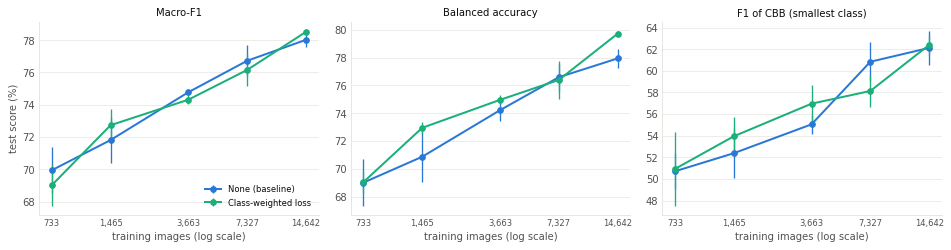

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, (k, name) in zip(axes, [("macro_f1", "Macro-F1"), ("balanced_acc", "Balanced accuracy"), ("f1_CBB", "F1 of CBB (smallest class)")]):
    for me in METHODS:
        d = lc.xs(me, level="method")
        ax.errorbar(d.n_train, 100 * d[k], yerr=100 * d[f"{k}_std"], fmt="o-", ms=5, lw=1.8,
                    color=COLOR[me], elinewidth=1.2, capsize=0, label=LABEL[me])
    ax.set_xscale("log")
    xt = sorted(lc.n_train.unique())
    ax.set_xticks(xt, [f"{int(round(v)):,}" for v in xt], fontsize=7.5)
    ax.minorticks_off()
    ax.set_xlabel("training images (log scale)")
    ax.set_title(name, fontsize=9)
    clean(ax)
axes[0].set_ylabel("test score (%)")
axes[0].legend(frameon=False, fontsize=7.5, loc="lower right")
fig.tight_layout()
save(fig, "learning_curve")
plt.show()

### 3.3 Where does it saturate, and what would more data be worth?

On a log scale the curve is roughly linear over a range, so a useful summary is the **gain per
doubling** of the training set between consecutive sizes. If the last gains (50% → 100%) are small,
the curve is flattening. The extrapolation fits `score = a + b·log2(n)` to the last three points
(25, 50, 100%) and predicts the score at 2× the current data. This is a rough, optimistic estimate:
learning curves usually bend further down, never up.

In [10]:
rows = []
for me in METHODS:
    d = lc.xs(me, level="method").sort_values("n_train")
    for (p0, a), (p1, b) in zip(d.iterrows(), list(d.iterrows())[1:]):
        dbl = np.log2(b.n_train / a.n_train)
        rows.append({"method": me, "from %": p0, "to %": p1,
                     "macro-F1 gain per doubling (pp)": 100 * (b.macro_f1 - a.macro_f1) / dbl,
                     "CBB F1 gain per doubling (pp)": 100 * (b.f1_CBB - a.f1_CBB) / dbl})
gains = pd.DataFrame(rows)
gains.to_csv(OUT / "gain_per_doubling.csv", index=False, float_format="%.3f")
display(gains.round(2))

ext = []
for me in METHODS:
    d = lc.xs(me, level="method").sort_values("n_train").tail(3)
    if len(d) == 3:
        b, a = np.polyfit(np.log2(d.n_train), d.macro_f1, 1)
        n_now = d.n_train.iloc[-1]
        ext.append({"method": me, "now (%)": 100 * d.macro_f1.iloc[-1],
                    "predicted at 2x data (%)": 100 * (a + b * np.log2(2 * n_now)),
                    "slope per doubling (pp)": 100 * b})
pd.DataFrame(ext).round(2)

,method,from %,to %,macro-F1 gain per doubling (pp),CBB F1 gain per doubling (pp)
0,none,5,10,1.87,1.67
1,none,10,25,2.24,2.02
2,none,25,50,1.95,5.79
3,none,50,100,1.30,1.28
4,weights,5,10,3.72,3.02
5,weights,10,25,1.20,2.28
6,weights,25,50,1.84,1.17
7,weights,50,100,2.36,4.27


,method,now (%),predicted at 2x data (%),slope per doubling (pp)
0,none,78.02,79.76,1.63
1,weights,78.52,80.53,2.10


## 4. Summary

Printed from the tables above; reflects only the runs finished so far.

In [11]:
print("A. Random vs grouped split (macro-F1 %, mean over runs, each on its own test set):")
for _, r in split_diff.iterrows():
    print(f"  {LABEL[r.method]:<20} grouped {r.grouped:.1f}  random {r.random:.1f}  "
          f"diff {r['random − grouped (pp)']:+.1f} pp  (Welch p={r['Welch p']:.2g}, runs {r['runs (grouped/random)']})")
print("\n   Accuracy on near-duplicate images (%):")
for (sp, sub, me), r in leak_tab.iterrows():
    if sub != "singletons":
        print(f"  {sp:<8} {sub:<30} {LABEL[me]:<20} {100*r.acc_mean:.1f}  (~{r.images_per_run:.0f} images/run, {int(r.runs)} runs)")
print("\nB. Learning curve (macro-F1 %, mean over folds 0-2):")
for (pct, me), r in lc.iterrows():
    print(f"  {pct:>3}%  n={int(r.n_train):>6,}  {LABEL[me]:<20} {100*r.macro_f1:.1f} ± {100*r.macro_f1_std:.1f}  "
          f"CBB F1 {100*r.f1_CBB:.1f}  ({int(r.runs)} runs)")
print("\nFiles in", OUT)
for f in sorted(OUT.iterdir()):
    print("  ", f.name)

A. Random vs grouped split (macro-F1 %, mean over runs, each on its own test set):
  None (baseline)      grouped 77.7  random 79.2  diff +1.5 pp  (Welch p=0.005, runs 5/3)
  Class-weighted loss  grouped 78.3  random 77.9  diff -0.4 pp  (Welch p=0.21, runs 5/3)

   Accuracy on near-duplicate images (%):
  grouped  group, unseen in train         None (baseline)      82.0  (~150 images/run, 5 runs)
  grouped  group, unseen in train         Class-weighted loss  83.1  (~150 images/run, 5 runs)
  random   leaked (group-mate in train)   None (baseline)      84.3  (~113 images/run, 3 runs)
  random   leaked (group-mate in train)   Class-weighted loss  84.2  (~113 images/run, 3 runs)

B. Learning curve (macro-F1 %, mean over folds 0-2):
    5%  n=   733  None (baseline)      69.9 ± 1.4  CBB F1 50.7  (3 runs)
    5%  n=   733  Class-weighted loss  69.0 ± 1.3  CBB F1 50.9  (3 runs)
   10%  n= 1,465  None (baseline)      71.8 ± 1.4  CBB F1 52.4  (3 runs)
   10%  n= 1,465  Class-weighted loss  72.